# 01 — EDA & Feature Selection

**Project:** TG-graph — Graph-Augmented XGBoost for Fraud Detection (TCC)  
**Dataset:** gen-fraud-graph (Santander, 2026)  
**Scope:** Exploratory Data Analysis + feature selection for the baseline model  

**Sections**
1. Load & merge data
2. Class imbalance
3. Missing value profile
4. amount distribution
5. Temporal fraud rate
6. Feature-dropping report (>90 % null + near-zero variance)
7. Identity vs. no-identity split statistics
8. Quick shallow XGBoost → top-20 feature importance
9. Save feature lists

In [12]:
import sys
sys.path.insert(0, '..')   # allow imports from project root when running from notebooks/

import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb

from src.features.load import load_train
from src.features.preprocessing import (
    ALWAYS_EXCLUDE,
    IDENTITY_COLS,
    drop_high_null_cols,
    drop_near_zero_variance,
    get_categorical_cols,
    label_encode_categoricals,
)
from src.features.split import identity_split, temporal_split, get_feature_cols

# Plot style
plt.rcParams.update({'figure.dpi': 120, 'font.family': 'DejaVu Sans'})
sns.set_style('whitegrid')
PALETTE = {'fraud': '#E63946', 'legit': '#457B9D'}

Path('../results').mkdir(exist_ok=True)
print('Environment ready')

Environment ready


---
## 1. Load & Merge Data

Left-join `train_transaction` with `train_identity` on `tx_id`.  
Transactions without a match retain NaN in all identity columns — this is the routing signal for Model A vs. Model B.

In [13]:
df = load_train(verbose=True)
print(f"\nMerged shape: {df.shape}")
df.head(3)

[load] Loaded 100,000 accounts.
[load] Loaded 900,052 total transactions (fraud rate: 0.006%).
[load] Final merged transactions shape: (900052, 16)

Merged shape: (900052, 16)


,tx_id,src_id,dst_id,amount,timestamp,description,embedding,isFraud,src_customer_name,src_balance,src_risk_score,src_creation_date,dst_customer_name,dst_balance,dst_risk_score,dst_creation_date
0,tx_450000,acc_37585,acc_29161,74.55,2024-01-26 16:25:10,restaurant payment,0.409559428691864|0.3617960810661316,0,Customer_37585,6377.32,0.8713,2023-01-01,Customer_29161,20321.75,0.7511,2023-01-01
1,tx_450001,acc_33596,acc_28274,472.29,2024-01-26 19:11:24,utility bill payment,0.4420679807662964|0.6814486980438232,0,Customer_33596,3778.89,0.8196,2023-01-01,Customer_28274,80262.19,0.0844,2023-01-01
2,tx_450002,acc_57876,acc_64818,244.97,2024-01-28 06:32:10,restaurant payment,0.8401355743408203|0.850598156452179,0,Customer_57876,84988.33,0.5865,2023-01-01,Customer_64818,28689.80,0.0345,2023-01-01


---
## 2. Class Imbalance

Total transactions : 900,052
Legitimate (0)     : 900,000  (99.99%)
Fraud      (1)     : 52  (0.01%)
Imbalance ratio    : 17307.7 : 1


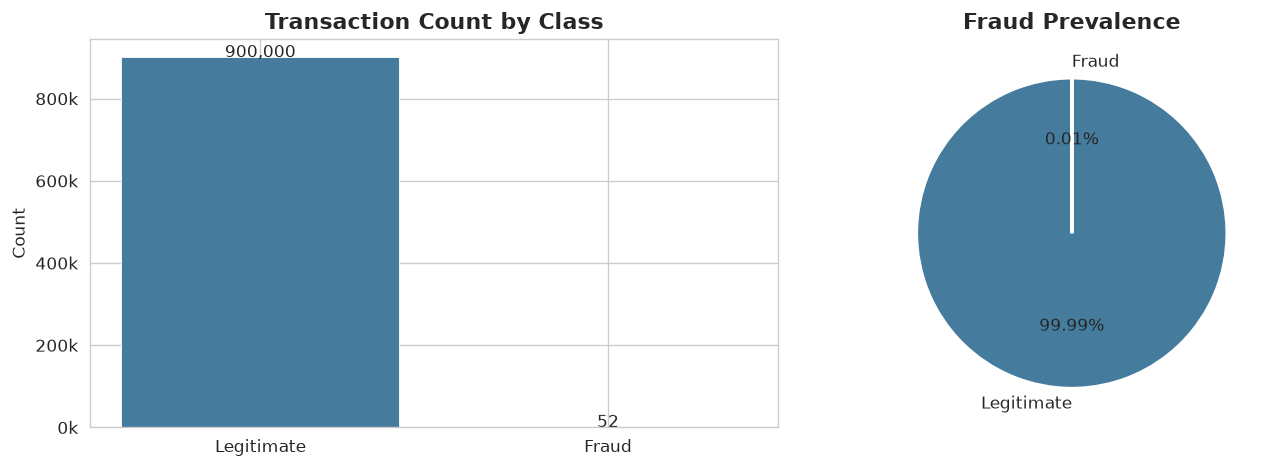

In [14]:
fraud_counts = df['isFraud'].value_counts()
fraud_rate   = df['isFraud'].mean()

print(f"Total transactions : {len(df):,}")
print(f"Legitimate (0)     : {fraud_counts[0]:,}  ({1-fraud_rate:.2%})")
print(f"Fraud      (1)     : {fraud_counts[1]:,}  ({fraud_rate:.2%})")
print(f"Imbalance ratio    : {fraud_counts[0]/fraud_counts[1]:.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
axes[0].bar(['Legitimate', 'Fraud'], [fraud_counts[0], fraud_counts[1]],
            color=[PALETTE['legit'], PALETTE['fraud']], edgecolor='white', linewidth=0.5)
axes[0].set_title('Transaction Count by Class', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))
for i, v in enumerate([fraud_counts[0], fraud_counts[1]]):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontsize=10)

# Pie chart
axes[1].pie([fraud_counts[0], fraud_counts[1]],
            labels=['Legitimate', 'Fraud'],
            colors=[PALETTE['legit'], PALETTE['fraud']],
            autopct='%1.2f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Fraud Prevalence', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../results/eda_class_imbalance.png', bbox_inches='tight')
plt.show()

---
## 3. Missing Value Profile

Columns with any null: 0 / 16
Columns with >90% null: 0
Columns with >50% null: 0
Columns with 0%  null: 16


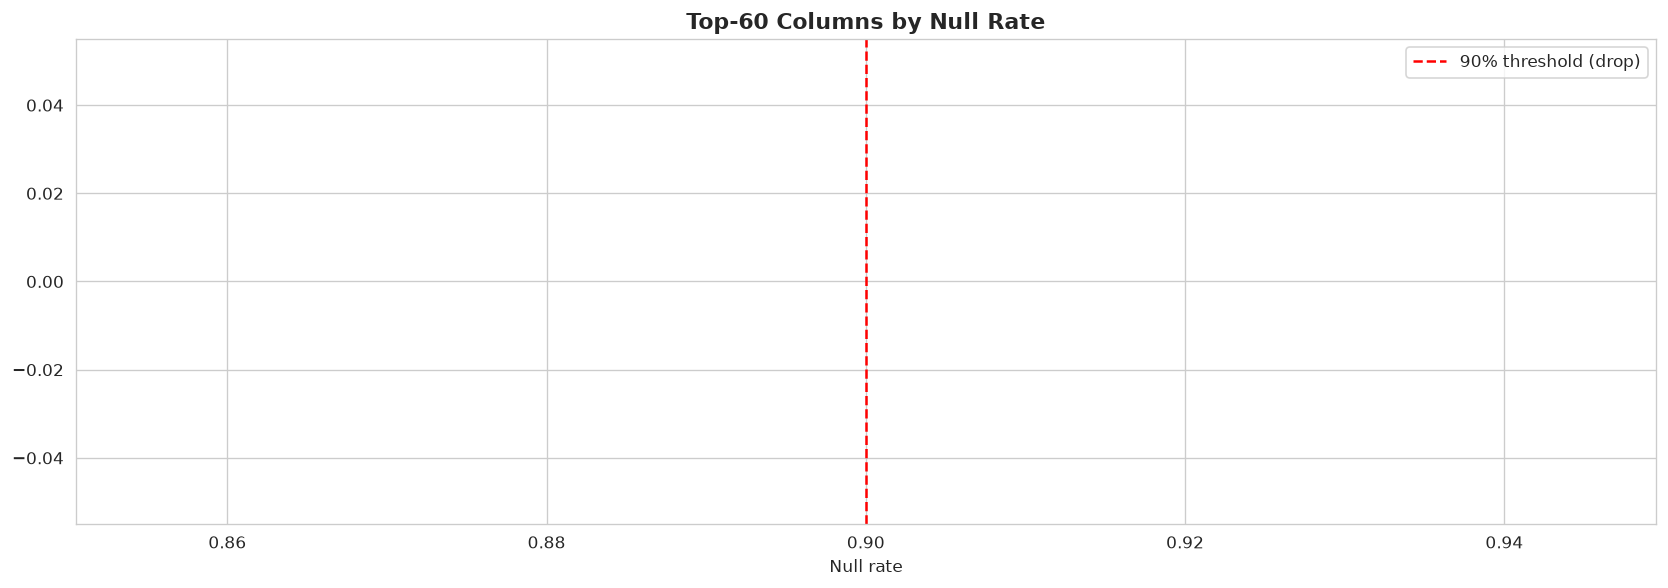

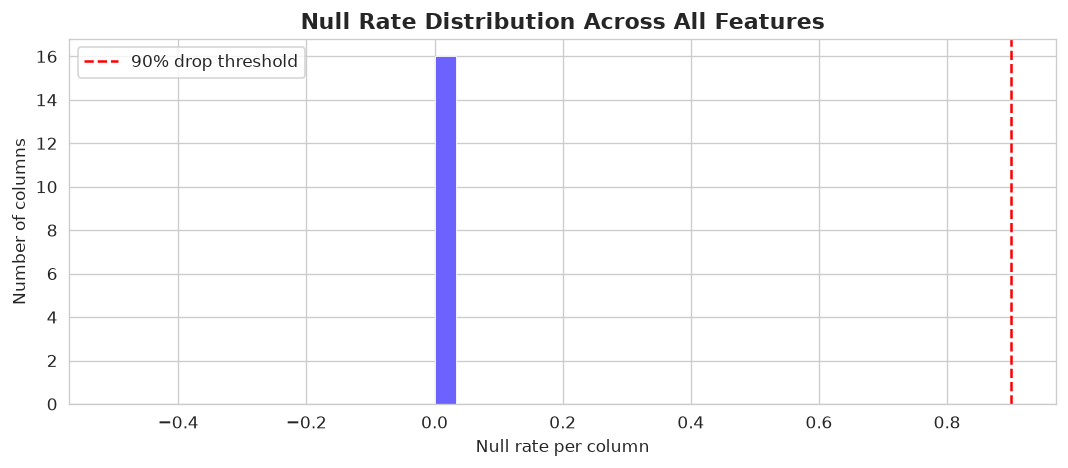

In [15]:
null_rates = df.isnull().mean().sort_values(ascending=False)
high_null  = null_rates[null_rates > 0.0]

print(f"Columns with any null: {len(high_null)} / {df.shape[1]}")
print(f"Columns with >90% null: {(null_rates > 0.9).sum()}")
print(f"Columns with >50% null: {(null_rates > 0.5).sum()}")
print(f"Columns with 0%  null: {(null_rates == 0).sum()}")

# Heatmap — top-60 null columns
top_null = high_null.head(60)
fig, ax = plt.subplots(figsize=(14, 5))
ax.barh(top_null.index[::-1], top_null.values[::-1],
        color=plt.cm.RdYlGn_r(top_null.values[::-1]))
ax.axvline(0.9, color='red', linestyle='--', lw=1.5, label='90% threshold (drop)')
ax.set_xlabel('Null rate')
ax.set_title('Top-60 Columns by Null Rate', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('../results/eda_null_rates.png', bbox_inches='tight')
plt.show()

# Null rate distribution
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(null_rates.values, bins=30, color='#6C63FF', edgecolor='white', linewidth=0.5)
ax.axvline(0.9, color='red', linestyle='--', lw=1.5, label='90% drop threshold')
ax.set_xlabel('Null rate per column')
ax.set_ylabel('Number of columns')
ax.set_title('Null Rate Distribution Across All Features', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('../results/eda_null_distribution.png', bbox_inches='tight')
plt.show()

---
## 4. amount Distribution

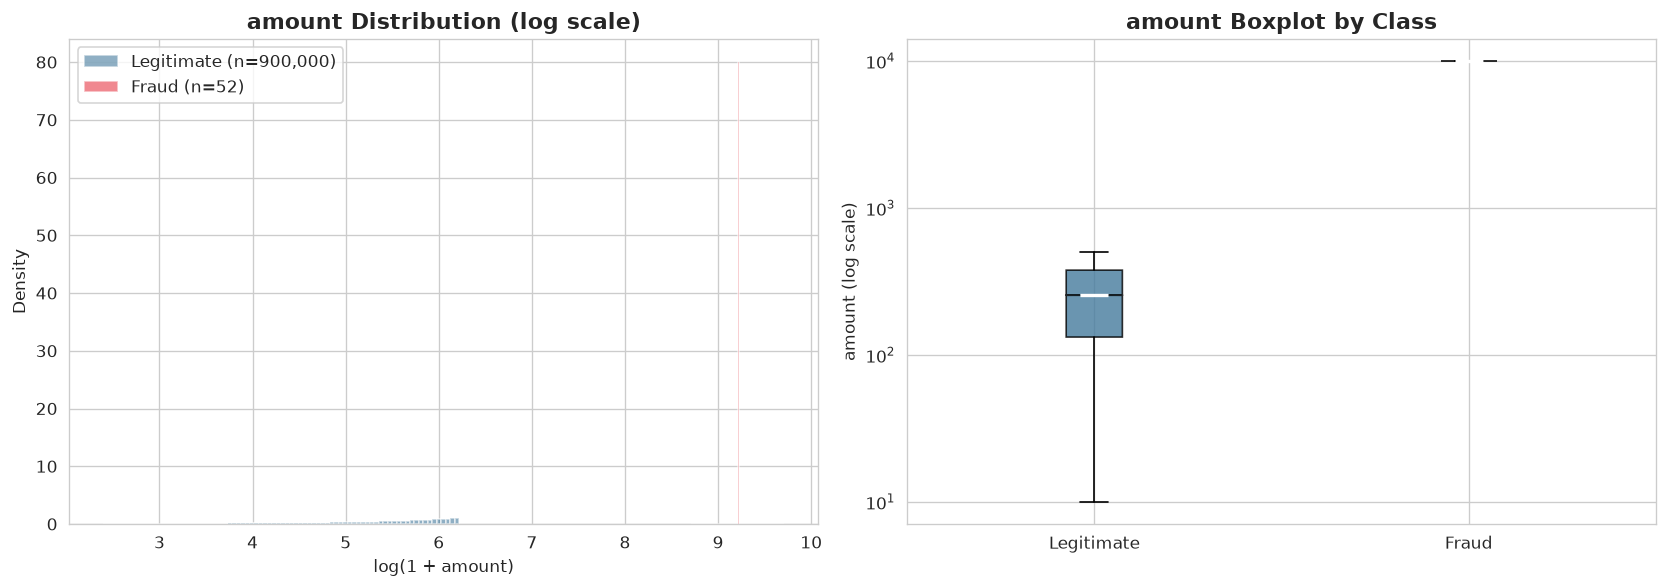

            count     mean     std     min      25%      50%     75%     max
isFraud                                                                     
0        900000.0   255.05  141.56    10.0   132.44   255.03   377.7   500.0
1            52.0  9999.00    0.00  9999.0  9999.00  9999.00  9999.0  9999.0


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Log-scale histogram by class
for label, color in [('Legitimate', PALETTE['legit']), ('Fraud', PALETTE['fraud'])]:
    is_fraud = 1 if label == 'Fraud' else 0
    vals = df.loc[df['isFraud'] == is_fraud, 'amount']
    axes[0].hist(np.log1p(vals), bins=80, alpha=0.6,
                 color=color, label=f'{label} (n={len(vals):,})', density=True)

axes[0].set_xlabel('log(1 + amount)')
axes[0].set_ylabel('Density')
axes[0].set_title('amount Distribution (log scale)', fontsize=13, fontweight='bold')
axes[0].legend()

# Boxplot
data_box = [
    df.loc[df['isFraud'] == 0, 'amount'],
    df.loc[df['isFraud'] == 1, 'amount'],
]
bp = axes[1].boxplot(data_box, patch_artist=True, notch=True,
                     medianprops={'color': 'white', 'linewidth': 2})
for patch, color in zip(bp['boxes'], [PALETTE['legit'], PALETTE['fraud']]):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
axes[1].set_xticklabels(['Legitimate', 'Fraud'])
axes[1].set_yscale('log')
axes[1].set_ylabel('amount (log scale)')
axes[1].set_title('amount Boxplot by Class', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../results/eda_transaction_amt.png', bbox_inches='tight')
plt.show()

# Summary stats
print(df.groupby('isFraud')['amount'].describe().round(2))

---
## 5. Temporal Fraud Rate

We bin transactions by `timestamp` and compute the fraud rate per bin to check for temporal stability.  
The vertical dashed line marks the train/val split boundary (80th percentile = 80th percentile of timestamp).

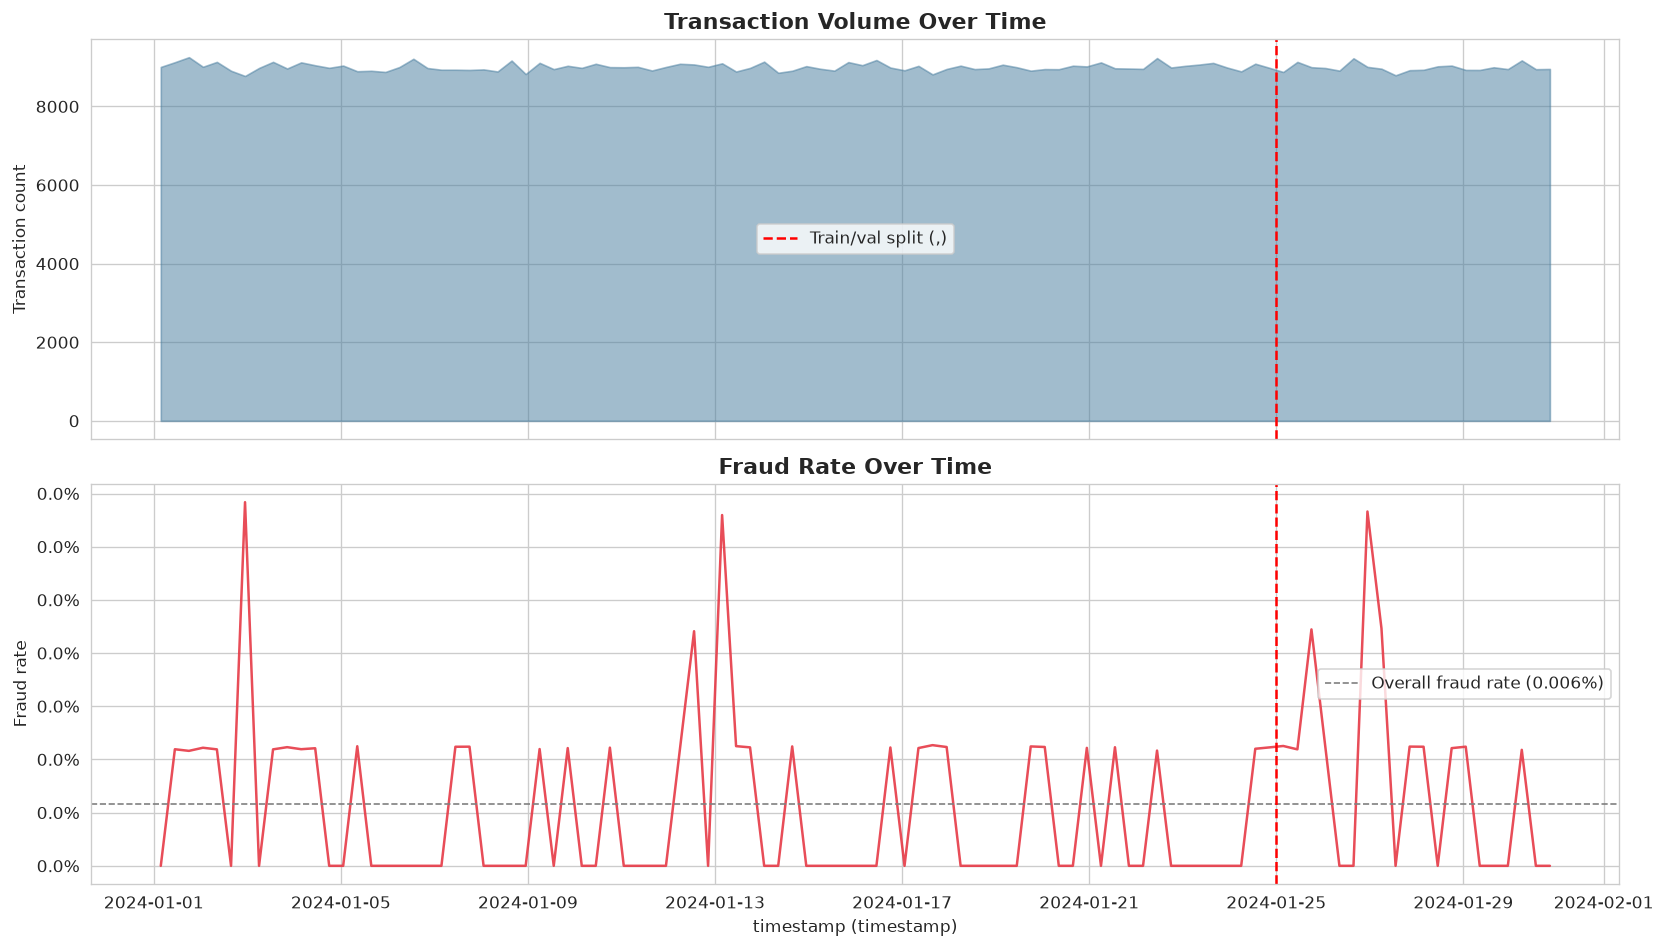

In [17]:
TEMPORAL_SPLIT_BOUNDARY = pd.to_datetime('2024-01-24 23:44:43')

df_temp = df[['timestamp', 'isFraud']].copy()
n_bins  = 100
df_temp['dt_bin'] = pd.cut(df_temp['timestamp'], bins=n_bins)

temporal_stats = df_temp.groupby('dt_bin', observed=True).agg(
    count=('isFraud', 'count'),
    fraud_rate=('isFraud', 'mean'),
    dt_mid=('timestamp', 'mean')
).dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Transaction volume
axes[0].fill_between(temporal_stats['dt_mid'], temporal_stats['count'],
                     alpha=0.5, color='#457B9D')
axes[0].axvline(pd.to_datetime('2024-01-24 23:44:43'), color='red', linestyle='--',
                lw=1.5, label=f'Train/val split ({pd.to_datetime('2024-01-24 23:44:43'):,})')
axes[0].set_ylabel('Transaction count')
axes[0].set_title('Transaction Volume Over Time', fontsize=13, fontweight='bold')
axes[0].legend()

# Fraud rate
axes[1].plot(temporal_stats['dt_mid'], temporal_stats['fraud_rate'],
             color=PALETTE['fraud'], lw=1.5, alpha=0.9)
axes[1].axhline(df['isFraud'].mean(), color='gray', linestyle='--',
                lw=1, label=f"Overall fraud rate ({df['isFraud'].mean():.3%})")
axes[1].axvline(pd.to_datetime('2024-01-24 23:44:43'), color='red', linestyle='--', lw=1.5)
axes[1].set_xlabel('timestamp (timestamp)')
axes[1].set_ylabel('Fraud rate')
axes[1].set_title('Fraud Rate Over Time', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))

plt.tight_layout()
plt.savefig('../results/eda_temporal_fraud_rate.png', bbox_inches='tight')
plt.show()

---
## 6. Feature-Dropping Report

Two rules (applied to the **training split only** to prevent leakage):  
- Drop columns with **> 90 % null rate**  
- Drop numerical columns with **near-zero variance** (CV < 0.01)

In [18]:
from src.features.preprocessing import save_dropped_cols

# Apply to training split only
train_df, val_df = temporal_split(df, verbose=True)

print("\n--- Applying feature dropping to training split ---")
train_clean, dropped_null   = drop_high_null_cols(train_df, threshold=0.90)
train_clean, dropped_var    = drop_near_zero_variance(train_clean, threshold=0.01)

print(f"\n{'='*50}")
print(f"Original columns      : {train_df.shape[1]}")
print(f"After null drop        : {train_df.shape[1] - len(dropped_null)}")
print(f"After variance drop    : {train_df.shape[1] - len(dropped_null) - len(dropped_var)}")
print(f"\nDropped (>90% null)  : {len(dropped_null)} columns")
print(f"Dropped (NZV)         : {len(dropped_var)} columns")

# Save for reproducibility
dropped_report = {
    'high_null': dropped_null,
    'near_zero_variance': dropped_var,
}
save_dropped_cols(dropped_report, path='../results/dropped_columns.json')

# Show first 20 dropped-null columns
print(f"\nSample dropped (null): {dropped_null[:20]}")

[split] temporal split:
  train: 720,041 (80.0%) | fraud rate: 0.005%
  val:   180,011 (20.0%) | fraud rate: 0.008%

--- Applying feature dropping to training split ---
[preprocess] drop_high_null: 0 columns dropped (null rate > 90%)
[preprocess] drop_near_zero_variance: 0 columns dropped (CV < 0.01)

Original columns      : 16
After null drop        : 16
After variance drop    : 16

Dropped (>90% null)  : 0 columns
Dropped (NZV)         : 0 columns
[preprocess] Dropped column lists saved → ../results/dropped_columns.json

Sample dropped (null): []


---
## 7. Identity vs. No-Identity Split Statistics

[split] identity routing:
  Group A (even acc): 359,960 (50.0%) | fraud: 0.005%
  Group B (odd acc) : 360,081 (50.0%) | fraud: 0.006%

--- Group statistics ---
                     Group      N Fraud rate Avg amount
 A (no identity — Model A) 359960     0.005%    $255.50
B (has identity — Model B) 360081     0.006%    $255.42


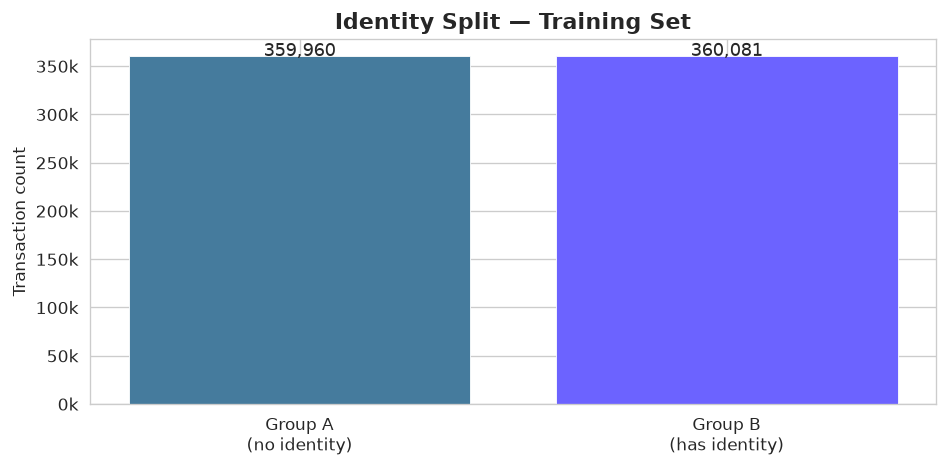

In [19]:
group_a_train, group_b_train = identity_split(train_clean, verbose=True)

print("\n--- Group statistics ---")
stats = pd.DataFrame({
    'Group': ['A (no identity — Model A)', 'B (has identity — Model B)'],
    'N': [len(group_a_train), len(group_b_train)],
    'Fraud rate': [group_a_train['isFraud'].mean(), group_b_train['isFraud'].mean()],
    'Avg amount': [
        group_a_train['amount'].mean(),
        group_b_train['amount'].mean()
    ],
})
stats['Fraud rate'] = stats['Fraud rate'].map('{:.3%}'.format)
stats['Avg amount'] = stats['Avg amount'].map('${:.2f}'.format)
print(stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
groups = ['Group A\n(no identity)', 'Group B\n(has identity)']
ns = [len(group_a_train), len(group_b_train)]
bars = ax.bar(groups, ns, color=[PALETTE['legit'], '#6C63FF'], edgecolor='white', linewidth=0.5)
ax.set_ylabel('Transaction count')
ax.set_title('Identity Split — Training Set', fontsize=13, fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))
for bar, n in zip(bars, ns):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
            f'{n:,}', ha='center', fontsize=11)
plt.tight_layout()
plt.savefig('../results/eda_identity_split.png', bbox_inches='tight')
plt.show()

---
## 8. Quick Shallow XGBoost → Top-20 Feature Importance

Train a very shallow model (max_depth=3, 100 trees) on the full training set  
to get a first-pass feature importance ranking. **No hyperparameter tuning.**

In [20]:
from src.features.split import get_feature_cols
from src.models.baseline import get_xgb_params

# Encode categoricals on the cleaned training set
cat_cols = get_categorical_cols(train_clean)
train_enc, encoders = label_encode_categoricals(train_clean, cat_cols, verbose=True)

# Feature columns — use all (transaction) features for the quick model
feat_cols = get_feature_cols(train_enc, include_identity=False)
print(f"Transaction feature count: {len(feat_cols)}")

X_quick = train_enc[feat_cols]
y_quick = train_enc['isFraud']

# Quick shallow model
quick_params = get_xgb_params(scale_pos_weight=y_quick.value_counts()[0]/y_quick.value_counts()[1])
quick_params.update({'n_estimators': 100, 'max_depth': 3, 'verbosity': 0})

import xgboost as xgb
quick_model = xgb.XGBClassifier(**quick_params)
quick_model.fit(X_quick, y_quick)
print('Quick model trained.')

[preprocess] label_encode: 0 categorical columns encoded
Transaction feature count: 1
Quick model trained.


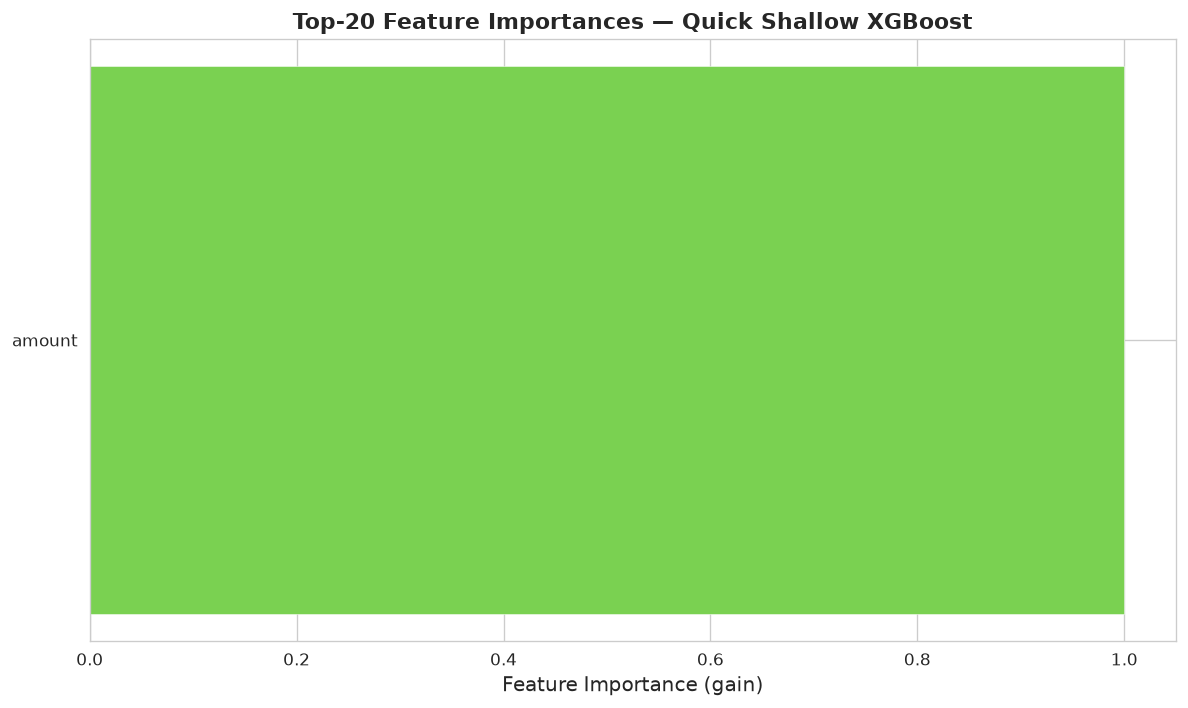


Top-20 features:
   1. amount                    1.0000


In [21]:
importances = pd.Series(
    quick_model.feature_importances_, index=feat_cols
).sort_values(ascending=False)

top20 = importances.head(20)

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0.2, 0.8, 20))
ax.barh(top20.index[::-1], top20.values[::-1], color=colors[::-1], edgecolor='white', linewidth=0.3)
ax.set_xlabel('Feature Importance (gain)', fontsize=12)
ax.set_title('Top-20 Feature Importances — Quick Shallow XGBoost', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/eda_top20_importance.png', bbox_inches='tight')
plt.show()

print("\nTop-20 features:")
for i, (feat, imp) in enumerate(top20.items(), 1):
    print(f"  {i:2d}. {feat:<25s} {imp:.4f}")

---
## 9. Save Feature Lists

In [22]:
# Full feature sets (after dropping, before encoding) for use in notebook 02
all_cols_after_drop = [c for c in train_clean.columns]
feat_cols_A = get_feature_cols(train_clean, include_identity=False)  # Model A
feat_cols_B = get_feature_cols(train_clean, include_identity=True)   # Model B

feature_lists = {
    'all_columns_after_dropping': all_cols_after_drop,
    'model_A_features': feat_cols_A,
    'model_B_features': feat_cols_B,
    'categorical_cols': cat_cols,
    'top20_importance': top20.index.tolist(),
    'n_features_A': len(feat_cols_A),
    'n_features_B': len(feat_cols_B),
}

Path('../results').mkdir(exist_ok=True)
with open('../results/feature_lists.json', 'w') as f:
    json.dump(feature_lists, f, indent=2)

print('Feature lists saved → results/feature_lists.json')
print(f"  Model A features: {len(feat_cols_A)}")
print(f"  Model B features: {len(feat_cols_B)}")
print(f"  Categorical cols: {len(cat_cols)}")

Feature lists saved → results/feature_lists.json
  Model A features: 1
  Model B features: 5
  Categorical cols: 0
